# The Palisades fire from a virtual Zarr cube

The cube holds two weeks of GOES-18 fire detections (2025-01-07 to 2025-01-20 UTC) for the full CONUS scene. This notebook uses the Palisades fire as its example and plots its fire radiative power (FRP). Change `BOX` to look at any other place in the scene. The notebook starts from the Portolan catalog, not from a URL to the data, so it also tests how far the catalog metadata gets a reader.

The cube is virtual. It holds byte-range references into NOAA's netCDF files in the public `noaa-goes18` bucket. Every pixel this notebook reads comes from NOAA's bucket. The approach comes from Earthmover's [GOES-16 virtual Zarr post](https://www.earthmover.io/blog/virtual-zarr/).

Run it from the repository with:

```bash
uv sync --group examples
uv run --group examples jupyter nbconvert --to notebook --execute --inplace examples/palisades-frp.ipynb
```

In [1]:
from pathlib import Path

# The catalog to start from. After the catalog is published, set this to the
# public catalog.json URL and set LOCAL_DATA to None.
ROOT = Path.cwd().parent if Path.cwd().name == "examples" else Path.cwd()
CATALOG = ROOT / "catalog" / "catalog.json"

# Until the data is published, asset hrefs that start with the public base are
# read from this local directory instead (data_dir in catalog.publish.yaml).
LOCAL_DATA = ROOT / "local" / "publish"

# The area to read, in longitude and latitude. Any box inside the CONUS scene
# works. This one is the Palisades fire, and it leaves out the Eaton fire, which
# started the same evening about 40 km to the east.
BOX = {"west": -118.70, "south": 34.00, "east": -118.45, "north": 34.15}

## 1. Find the data through the catalog

The root catalog links to the collection. The collection says what the cube holds and how to open it.

In [2]:
import pystac

root = pystac.Catalog.from_file(str(CATALOG))
collection = next(c for c in root.get_all_collections() if c.id == "goes-18-fdcc")
asset = collection.assets["icechunk"]

print(collection.title)
print("time:      ", collection.extent.temporal.intervals[0])
print("variables: ", list(collection.extra_fields["cube:variables"]))
print("asset href:", asset.href)
print("media type:", asset.media_type)
print("open with: ", asset.extra_fields["xarray:open_kwargs"])

GOES-18 ABI L2 Fire/Hot Spot Characterization, CONUS (virtual Zarr)
time:       [datetime.datetime(2025, 1, 7, 0, 2, 35, tzinfo=tzutc()), datetime.datetime(2025, 1, 20, 23, 57, 35, tzinfo=tzutc())]
variables:  ['Mask', 'DQF', 'Power', 'Temp', 'Area']
asset href: https://data.source.coop/<ACCOUNT>/goes-fdc/goes-18-fdcc/icechunk/
media type: application/vnd+zarr
open with:  {'engine': 'zarr', 'consolidated': False}


## 2. Open the cube

The asset says the cube is a Zarr v3 group in an Icechunk repository, and it gives the `xarray` arguments. It does not say that the chunks live in another bucket. Icechunk refuses to read a virtual chunk from a location the reader has not authorized, so the reader must configure NOAA's bucket as a *virtual chunk container* by hand. No field in the STAC `zarr` or `xarray` extensions carries that today. The collection README documents it, and this notebook copies it from there. This gap is one of the open questions for Zarr in Portolan ([portolan-spec#132](https://github.com/portolan-sdi/portolan-spec/issues/132)).

In [3]:
import os
import sys

# Icechunk warns that local storage is not safe for concurrent commits. This
# notebook only reads, so keep the output to errors.
os.environ.setdefault("ICECHUNK_LOG", "error")

import icechunk
import xarray as xr

sys.path.insert(0, str(ROOT / "tools"))
from publish import load_config  # noqa: E402

public_base = load_config(ROOT / "catalog.publish.yaml")["public_base"].rstrip("/")


def storage_for(href: str) -> icechunk.Storage:
    """Icechunk storage for an asset href, read locally until the data is published."""
    if LOCAL_DATA is not None and href.startswith(public_base):
        local = LOCAL_DATA / href[len(public_base):].strip("/")
        return icechunk.local_filesystem_storage(str(local))
    return icechunk.http_storage(href)


# Not in the catalog metadata. Copied from the collection README.
NOAA = "https://noaa-goes18.s3.amazonaws.com/"
config = icechunk.RepositoryConfig.default()
config.set_virtual_chunk_container(icechunk.VirtualChunkContainer(NOAA, icechunk.http_store()))
credentials = icechunk.containers_credentials({NOAA: icechunk.Credentials.HttpAccess()})

repo = icechunk.Repository.open(
    storage_for(asset.href), config=config, authorize_virtual_chunk_access=credentials
)
# Read the tagged snapshot, not the branch head. The tag pins exactly the data
# this notebook was run against, even after the cube grows.
print("tags:", sorted(repo.list_tags()))
session = repo.readonly_session(tag="demo-2025-01")
open_kwargs = {k: v for k, v in asset.extra_fields["xarray:open_kwargs"].items() if k != "engine"}
ds = xr.open_zarr(session.store, **open_kwargs)
ds

tags: ['demo-2025-01']


<xarray.Dataset> Size: 420GB
Dimensions:  (time: 3996, y: 1500, x: 2500)
Coordinates:
  * time     (time) datetime64[ns] 32kB 2025-01-07T00:02:35.732040960 ... 202...
  * y        (y) float64 12kB 0.1282 0.1282 0.1281 ... 0.04438 0.04432 0.04427
  * x        (x) float64 20kB -0.06997 -0.06992 -0.06986 ... 0.06992 0.06997
Data variables:
    Mask     (time, y, x) float32 60GB ...
    Power    (time, y, x) float32 60GB ...
    Temp     (time, y, x) float64 120GB ...
    Area     (time, y, x) float64 120GB ...
    DQF      (time, y, x) float32 60GB ...
Attributes:
    goes_fdc:signature:  {"Area": {"add_offset": 4000.0, "chunks": [250, 250]...

## 3. Cut out the fire

The cube is on the ABI fixed grid, where `x` and `y` are scan angles in radians, not longitude and latitude. The collection carries the grid's projection as WKT2 in `proj:wkt2`, so the box converts with `pyproj` and no GOES-specific code. Projected metres divided by the satellite height give the scan angle.

In [4]:
import pyproj

crs = pyproj.CRS.from_wkt(asset.extra_fields["proj:wkt2"])
height = crs.to_cf()["perspective_point_height"]
to_grid = pyproj.Transformer.from_crs("EPSG:4326", crs, always_xy=True)

x0, y0 = (v / height for v in to_grid.transform(BOX["west"], BOX["south"]))
x1, y1 = (v / height for v in to_grid.transform(BOX["east"], BOX["north"]))

# y runs north to south on the fixed grid, so its slice is reversed.
fire = ds.sel(x=slice(x0, x1), y=slice(y1, y0))
print(f"{fire.sizes['y']} x {fire.sizes['x']} pixels, {fire.sizes['time']} scans")

6 x 9 pixels, 3996 scans


In [5]:
import time

import numpy as np

# Fire categories in the FDC mask: 10 to 15 and 30 to 35.
FIRE_CODES = [10, 11, 12, 13, 14, 15, 30, 31, 32, 33, 34, 35]

t0 = time.perf_counter()
frp = fire.Power.where(fire.Power > 0).sum(("y", "x")).compute()
pixels = fire.Mask.isin(FIRE_CODES).sum(("y", "x")).compute()
elapsed = time.perf_counter() - t0
print(f"read {fire.sizes['time']} scans in {elapsed:.1f} s")
print(f"peak FRP {float(frp.max()):,.0f} MW at {np.datetime_as_string(frp.idxmax().values, unit='m')}Z")
first = pixels.time.where(pixels > 0, drop=True)
print(f"first fire pixel at {np.datetime_as_string(first.values[0], unit='s')}Z")

read 3996 scans in 106.9 s
peak FRP 26,255 MW at 2025-01-08T07:12Z
first fire pixel at 2025-01-07T18:32:35Z


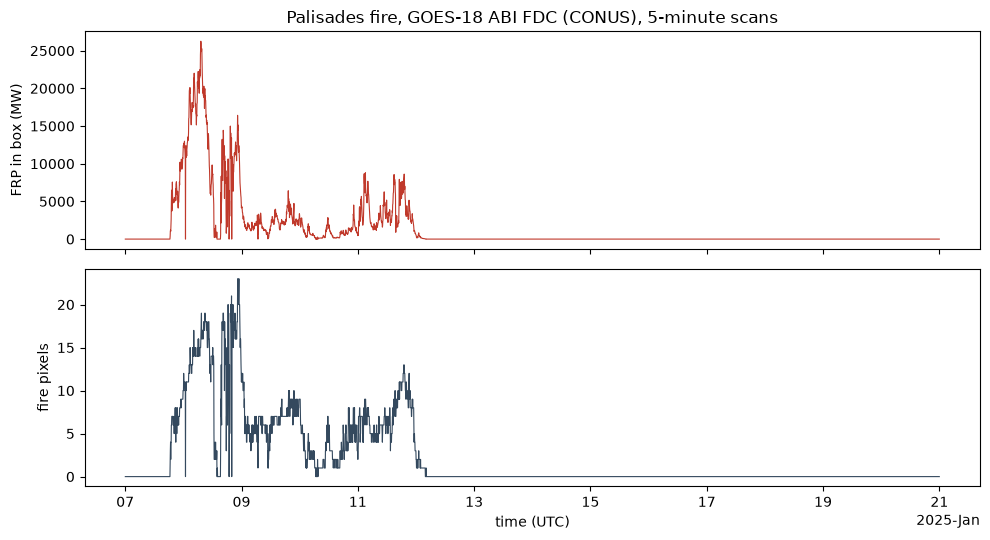

In [6]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
frp.plot(ax=ax1, lw=0.8, color="#c0392b")
ax1.set_ylabel("FRP in box (MW)")
ax1.set_xlabel("")
ax1.set_title("Palisades fire, GOES-18 ABI FDC (CONUS), 5-minute scans")
pixels.plot(ax=ax2, lw=0.8, color="#34495e")
ax2.set_ylabel("fire pixels")
ax2.set_xlabel("time (UTC)")
fig.tight_layout()

## 4. What the cube saved

Without the cube, the same answer starts with a list of every file in the window, then a download of each one. With the cube, the reader asks for the chunks that cover the box and nothing else.

In [7]:
ys = np.flatnonzero((ds.y <= y1).values & (ds.y >= y0).values)
xs = np.flatnonzero((ds.x >= x0).values & (ds.x <= x1).values)
cy, cx = ds.Power.encoding["chunks"][1:]
tiles = len(set(ys // cy)) * len(set(xs // cx))
per_file = (ds.sizes["y"] // cy) * (ds.sizes["x"] // cx)

print(f"netCDF files in the window:        {ds.sizes['time']:,}")
print(f"chunks per variable per file:      {per_file}")
print(f"chunks the box needs per variable: {tiles}")
print(f"chunk requests for Power and Mask: {2 * tiles * ds.sizes['time']:,}")

netCDF files in the window:        3,996
chunks per variable per file:      60
chunks the box needs per variable: 1
chunk requests for Power and Mask: 7,992


## What the catalog could not say

- **The virtual chunk container.** The reader needs NOAA's `https` prefix authorized before any read. The catalog has no field for it.
- **The store is a directory.** The `icechunk` asset is a repository, not one object, so it has no single `file:checksum` or `file:size`.
- **One grid per cube.** A virtual cube inherits the grid of its files. GOES-18 moved from -89.5 to -137.0 degrees in 2022, so its early files cannot join this cube. The catalog has no way to say which era a cube covers or to link the cube for another era.

These notes go to [portolan-spec#132](https://github.com/portolan-sdi/portolan-spec/issues/132).